# Using Machine Learning to Predict Financial Risk and Potential Losses Among Retail Investors on Digital Investment Platforms
**Dataset:** Robinhood Stock Popularity History (Kaggle) — number of users holding each stock over time.



## 1. Setup

In [18]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, roc_curve, classification_report)
warnings.filterwarnings("ignore"); sns.set_style("whitegrid")
RANDOM_STATE = 42
DATA_FILE = "robin_dataset.csv"     
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15   
TUNE_STEP = 4                      
os.makedirs("outputs", exist_ok=True)
def save_show(n):
    plt.tight_layout(); plt.savefig(f"outputs/{n}.png", dpi=150, bbox_inches="tight"); plt.show()

## 2. Load data and removed the duplicated block

In [19]:
raw = pd.read_csv(DATA_FILE)
print("Raw shape:", raw.shape); print(raw.isnull().sum())
bad = raw["name"] == "robin_dataset"
clean = raw[~bad].copy()
chk = raw[bad][["timestamp","users_holding"]].merge(clean[["timestamp","users_holding"]].drop_duplicates(), how="left", indicator=True)
print("Rows labelled 'robin_dataset' (merge error):", bad.sum(), "| real rows:", len(clean))
print("Share of those rows that duplicate real rows:", round((chk["_merge"]=="both").mean(), 4))
clean["timestamp"] = pd.to_datetime(clean["timestamp"])
n0 = len(clean)
clean = clean.drop_duplicates(["name","timestamp"]).sort_values(["name","timestamp"]).reset_index(drop=True)
print("Extra duplicate (name, timestamp) rows removed:", n0-len(clean))
print("Stocks:", clean["name"].nunique(), "|", clean["timestamp"].min(), "->", clean["timestamp"].max())

Raw shape: (1214151, 3)
timestamp        0
users_holding    0
name             0
dtype: int64
Rows labelled 'robin_dataset' (merge error): 809434 | real rows: 404717
Share of those rows that duplicate real rows: 1.0
Extra duplicate (name, timestamp) rows removed: 0
Stocks: 31 | 2018-05-02 04:50:16 -> 2020-02-17 08:50:29


## 3. 
For each stock, ordered by time:
* `popularity_change` = users_holding − previous users_holding
* `growth_rate` = popularity_change / previous users_holding
* `rolling_avg` = mean of the last 7 observations
* `momentum` = users_holding − users_holding 7 observations earlier
* `risk` = 1 if `popularity_change < 0` else 0

In [20]:
g = clean.groupby("name")["users_holding"]
df = clean.copy()
df["popularity_change"] = g.diff(1)
df["growth_rate"] = g.pct_change(1)
df["rolling_avg"] = g.transform(lambda s: s.rolling(7).mean())
df["momentum"] = g.diff(7)
df["risk"] = (df["popularity_change"] < 0).astype(int)
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna(subset=["popularity_change","growth_rate","rolling_avg","momentum"]).reset_index(drop=True)
print("Rows after computing original features:", len(df))
print(df["risk"].value_counts(), "\n", df["risk"].value_counts(normalize=True).round(4))

Rows after computing original features: 394922
risk
0    373755
1     21167
Name: count, dtype: int64 
 risk
0    0.9464
1    0.0536
Name: proportion, dtype: float64


## 4.
To predict whether the current observation shows a decrease, the model may only use what was known before it. Each original feature is therefore lagged by one observation (`prev_*`). Two extra past-only descriptors are added: the count of decreases over the last 7 observations and the volatility of the growth rate (both also lagged).

In [21]:
g2 = df.groupby("name")
df["prev_popularity_change"] = g2["popularity_change"].shift(1)
df["prev_growth_rate"]       = g2["growth_rate"].shift(1)
df["prev_rolling_avg"]       = g2["rolling_avg"].shift(1)
df["prev_momentum"]          = g2["momentum"].shift(1)
df["prev_users_holding"]     = g2["users_holding"].shift(1)
df["down_count_7"]           = g2["risk"].transform(lambda s: s.shift(1).rolling(7).sum())
df["growth_vol_7"]           = g2["growth_rate"].transform(lambda s: s.shift(1).rolling(7).std())

FEATURES = ["prev_popularity_change","prev_growth_rate","prev_rolling_avg","prev_momentum",
            "prev_users_holding","down_count_7","growth_vol_7"]
data = df.dropna(subset=FEATURES).sort_values("timestamp").reset_index(drop=True)
X_all, y_all = data[FEATURES], data["risk"]
print("Modelling rows:", len(data), "| positive rate:", round(y_all.mean(), 4))

for f in FEATURES:
    assert not np.allclose(data[f].fillna(0).values, data["growth_rate"].fillna(0).values), f"{f} leaks growth_rate"
    assert not np.allclose(data[f].fillna(0).values, data["popularity_change"].fillna(0).values), f"{f} leaks popularity_change"
print("Leakage check passed: no feature equals the current growth_rate / popularity_change.")

Modelling rows: 394705 | positive rate: 0.0536
Leakage check passed: no feature equals the current growth_rate / popularity_change.


## 5. Exploratory data analysis

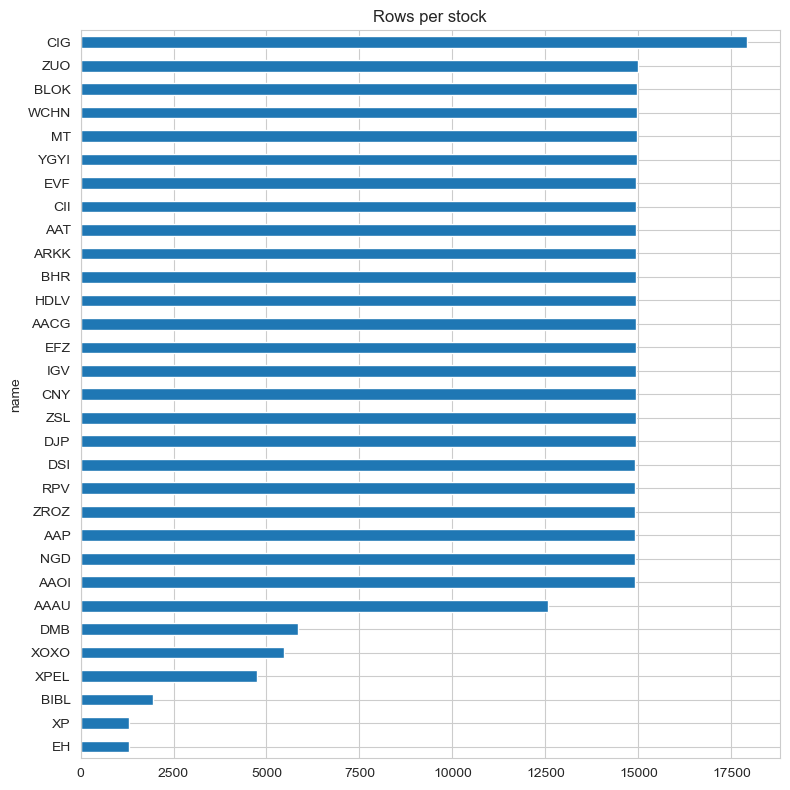

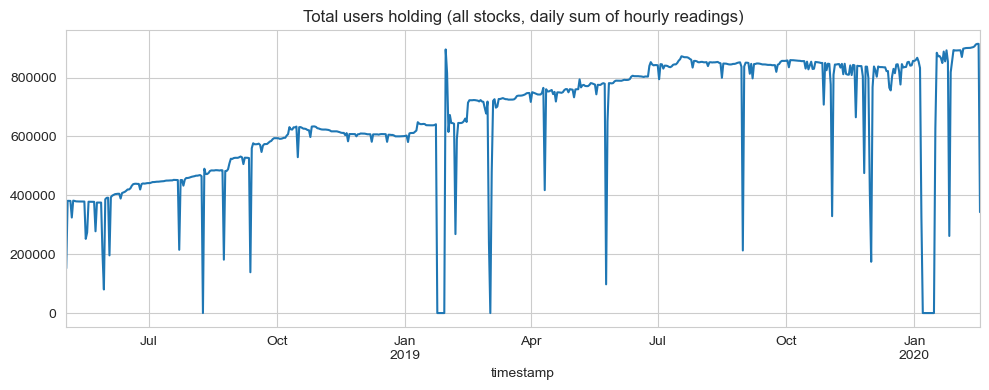

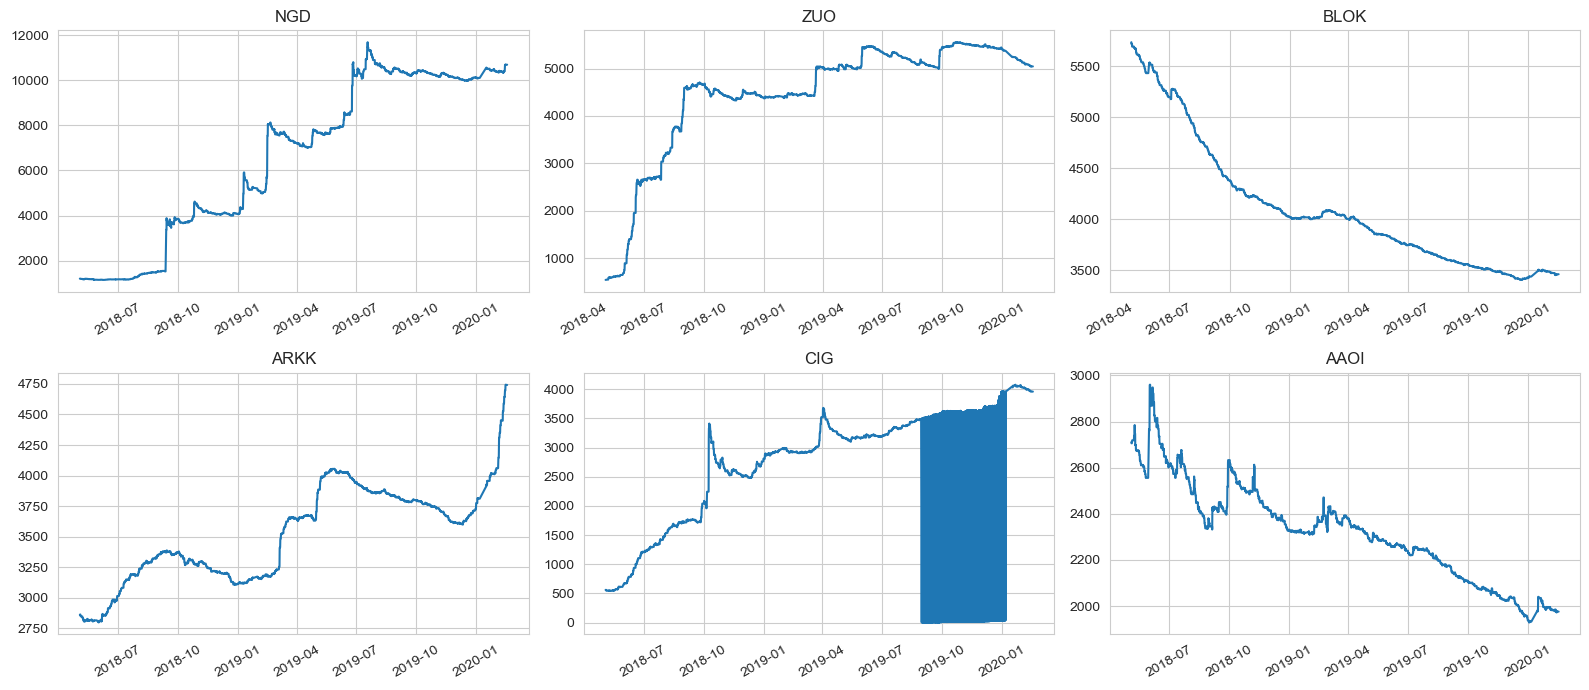

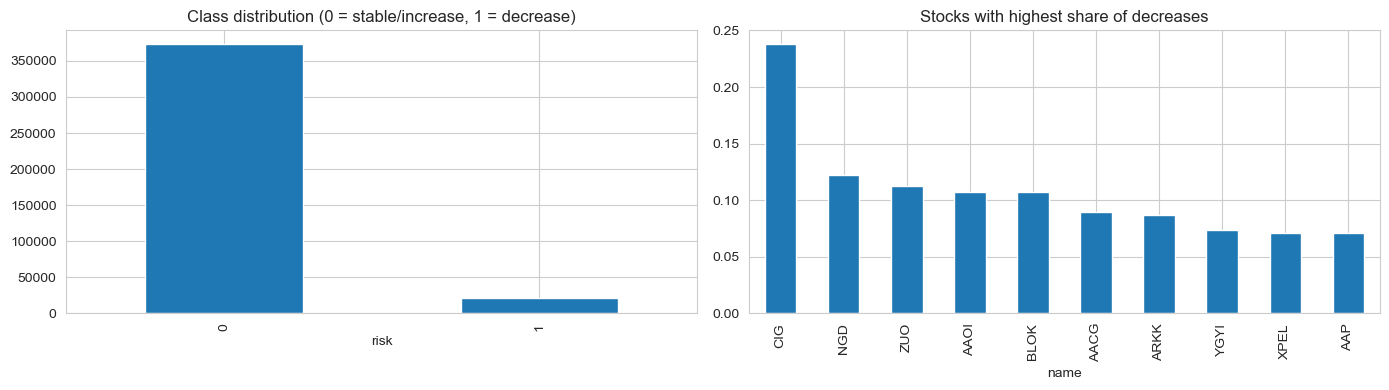

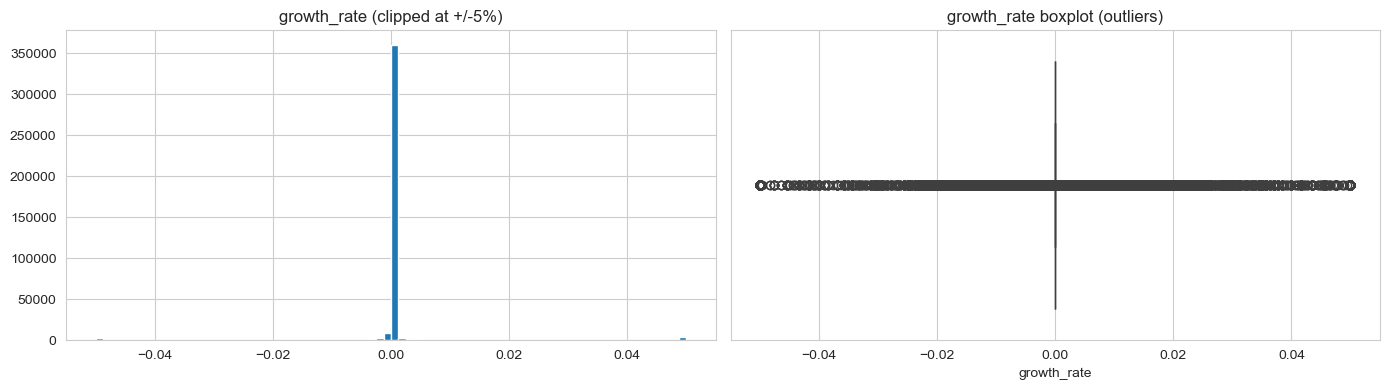

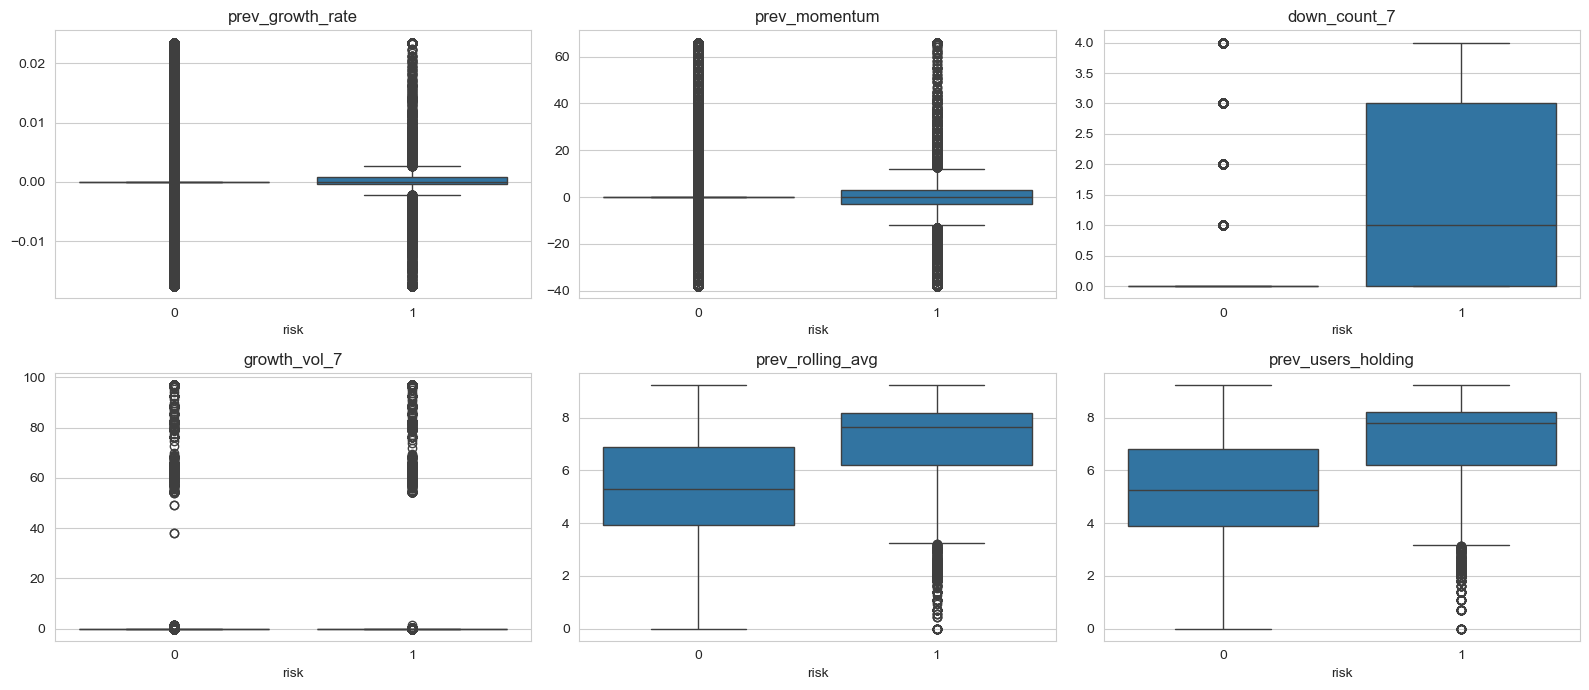

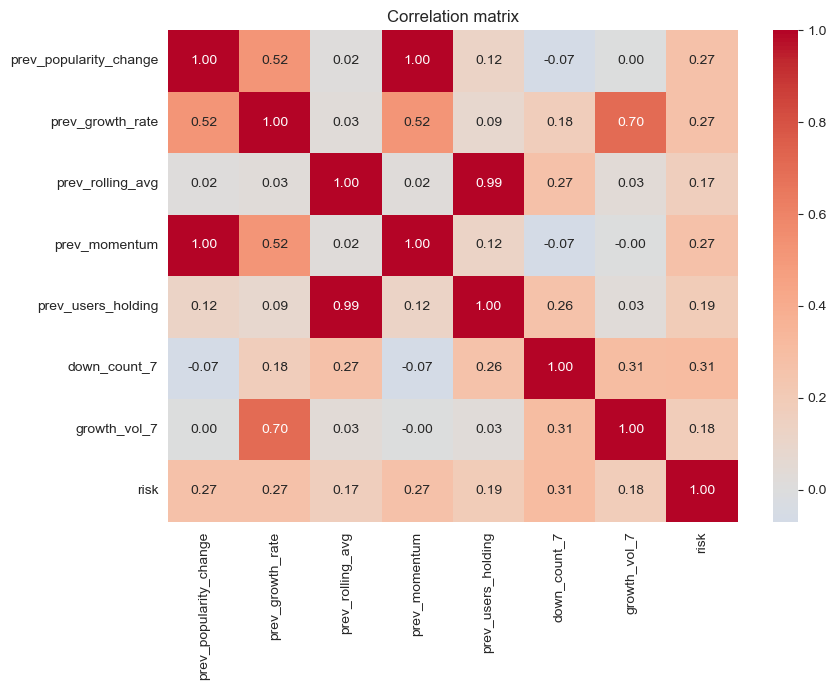

,count,mean,std,min,25%,50%,75%,max
prev_popularity_change,394705.0,0.0562,445.2041,-3930.0000,0.0,0.0000,0.0000,3930.0000
prev_growth_rate,394705.0,2.5770,40.0827,-0.9992,0.0,0.0000,0.0000,1176.3333
prev_rolling_avg,394705.0,1094.8330,1856.9649,1.0000,57.0,232.2857,1172.4286,11564.1429
prev_momentum,394705.0,0.3937,445.2933,-3931.0000,0.0,0.0000,0.0000,4009.0000
prev_users_holding,394705.0,1095.0017,1870.2101,1.0000,55.0,221.0000,1100.0000,11687.0000
down_count_7,394705.0,0.3753,0.9368,0.0000,0.0,0.0000,0.0000,7.0000
growth_vol_7,394705.0,2.7763,30.3111,0.0000,0.0,0.0000,0.0002,629.0732
users_holding,394705.0,1095.0574,1870.2786,0.0000,55.0,221.0000,1100.0000,11687.0000


In [22]:
model_df = data
model_df.groupby("name").size().sort_values().plot(kind="barh", figsize=(8,8), title="Rows per stock"); save_show("eda_01_rows_per_stock")
model_df.set_index("timestamp").groupby(pd.Grouper(freq="D"))["users_holding"].sum().plot(figsize=(10,4), title="Total users holding (all stocks, daily sum of hourly readings)"); save_show("eda_02_total_holders")
top6 = model_df.groupby("name")["users_holding"].mean().nlargest(6).index
fig, ax = plt.subplots(2,3, figsize=(16,7))
for a,n in zip(ax.ravel(), top6):
    d = model_df[model_df["name"]==n]; a.plot(d["timestamp"], d["users_holding"]); a.set_title(n); a.tick_params(axis="x", rotation=30)
save_show("eda_03_top_stocks")
fig, ax = plt.subplots(1,2, figsize=(14,4))
model_df["risk"].value_counts().sort_index().plot(kind="bar", ax=ax[0], title="Class distribution (0 = stable/increase, 1 = decrease)")
model_df.groupby("name")["risk"].mean().sort_values(ascending=False).head(10).plot(kind="bar", ax=ax[1], title="Stocks with highest share of decreases")
save_show("eda_04_class_balance")
fig, ax = plt.subplots(1,2, figsize=(14,4))
model_df["growth_rate"].clip(-0.05, 0.05).hist(bins=80, ax=ax[0]); ax[0].set_title("growth_rate (clipped at +/-5%)")
sns.boxplot(x=model_df["growth_rate"].clip(-0.05,0.05), ax=ax[1]); ax[1].set_title("growth_rate boxplot (outliers)")
save_show("eda_05_growth_rate")
fig, ax = plt.subplots(2,3, figsize=(16,7))
for a,f in zip(ax.ravel(), ["prev_growth_rate","prev_momentum","down_count_7","growth_vol_7","prev_rolling_avg","prev_users_holding"]):
    lo,hi = model_df[f].quantile([0.01,0.99]); v = model_df[f].clip(lo,hi)
    sns.boxplot(x=model_df["risk"], y=np.log1p(v-v.min()) if f in ["prev_rolling_avg","prev_users_holding"] else v, ax=a); a.set_title(f); a.set_ylabel("")
save_show("eda_06_features_by_class")
plt.figure(figsize=(9,7)); sns.heatmap(model_df[FEATURES+["risk"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); save_show("eda_07_correlation")
model_df[FEATURES+["users_holding"]].describe().T.round(4).to_csv("outputs/eda_summary_stats.csv")
model_df[FEATURES+["users_holding"]].describe().T.round(4)

## 6. Chronological split (train 70% / validation 15% / test 15%)

In [23]:
ts = np.sort(data["timestamp"].unique())
t1, t2 = ts[int(len(ts)*TRAIN_FRAC)], ts[int(len(ts)*(TRAIN_FRAC+VAL_FRAC))]
train, val, test = data[data.timestamp < t1], data[(data.timestamp >= t1) & (data.timestamp < t2)], data[data.timestamp >= t2]
for n,d in [("train",train),("val",val),("test",test)]:
    print(f"{n:5s} rows={len(d):7d}  {d.timestamp.min()} -> {d.timestamp.max()}  positive rate={d.risk.mean():.4f}")
X_train,y_train = train[FEATURES], train["risk"]; X_val,y_val = val[FEATURES], val["risk"]; X_test,y_test = test[FEATURES], test["risk"]

train rows= 276307  2018-05-03 12:31:00 -> 2019-08-14 13:06:26  positive rate=0.0470
val   rows=  58730  2019-08-14 13:06:36 -> 2019-11-12 14:08:13  positive rate=0.0758
test  rows=  59668  2019-11-12 14:08:25 -> 2020-02-17 08:50:29  positive rate=0.0624


## 7. Baselines

In [24]:
def metrics(y, pred, score=None):
    o = dict(Accuracy=accuracy_score(y,pred), Precision=precision_score(y,pred,zero_division=0),
             Recall=recall_score(y,pred,zero_division=0), F1=f1_score(y,pred,zero_division=0))
    if score is not None: o["ROC_AUC"]=roc_auc_score(y,score); o["PR_AUC"]=average_precision_score(y,score)
    return o
base = {}
base["Baseline: always 0"] = metrics(y_test, np.zeros(len(y_test),dtype=int), np.zeros(len(y_test)))
persist = (test["prev_popularity_change"] < 0).astype(int)
base["Baseline: persistence (previous change was a decrease)"] = metrics(y_test, persist, persist)
pd.DataFrame(base).T.round(4)

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Baseline: always 0,0.9376,0.0000,0.0000,0.000,0.5000,0.0624
Baseline: persistence (previous change was a decrease),0.9008,0.2049,0.2051,0.205,0.5761,0.0916


## 8. Models and hyperparameter tuning


In [25]:
Xt, yt = X_train.iloc[::TUNE_STEP], y_train.iloc[::TUNE_STEP]
tscv = TimeSeriesSplit(n_splits=3)

lr_s = RandomizedSearchCV(Pipeline([("sc",StandardScaler()),("clf",LogisticRegression(max_iter=2000,class_weight="balanced",random_state=RANDOM_STATE))]),
    {"clf__C":[0.001,0.01,0.1,1,10,100]}, n_iter=6, cv=tscv, scoring="average_precision", random_state=RANDOM_STATE, n_jobs=-1).fit(Xt, yt)
rf_s = RandomizedSearchCV(RandomForestClassifier(class_weight="balanced",random_state=RANDOM_STATE,n_jobs=-1),
    {"n_estimators":[100,200],"max_depth":[6,10,14,None],"min_samples_leaf":[5,20,50],"max_features":["sqrt",0.5]},
    n_iter=8, cv=tscv, scoring="average_precision", random_state=RANDOM_STATE, n_jobs=-1).fit(Xt, yt)
gb_s = RandomizedSearchCV(GradientBoostingClassifier(random_state=RANDOM_STATE),
    {"n_estimators":[100,200],"learning_rate":[0.05,0.1],"max_depth":[2,3,4],"subsample":[0.7,1.0]},
    n_iter=8, cv=tscv, scoring="average_precision", random_state=RANDOM_STATE, n_jobs=-1).fit(Xt, yt, sample_weight=compute_sample_weight("balanced", yt))
tuned = {"Logistic Regression":lr_s, "Random Forest":rf_s, "Gradient Boosting":gb_s}
for k,s in tuned.items(): print(f"{k}: CV PR-AUC={s.best_score_:.4f} params={s.best_params_}")
json.dump({k:{**s.best_params_,"cv_pr_auc":float(s.best_score_)} for k,s in tuned.items()}, open("outputs/best_params.json","w"), indent=2, default=str)

Logistic Regression: CV PR-AUC=0.2068 params={'clf__C': 0.01}
Random Forest: CV PR-AUC=0.3473 params={'n_estimators': 100, 'min_samples_leaf': 50, 'max_features': 'sqrt', 'max_depth': None}
Gradient Boosting: CV PR-AUC=0.3392 params={'subsample': 1.0, 'n_estimators': 100, 'max_depth': 2, 'learning_rate': 0.1}


## 9. Validation — choose decision thresholds

In [26]:
def best_thr(y, sc):
    p,r,t = precision_recall_curve(y, sc); f = 2*p[:-1]*r[:-1]/(p[:-1]+r[:-1]+1e-12); return t[np.argmax(f)]
def fit_est(est, X, y, gb):
    return est.fit(X, y, sample_weight=compute_sample_weight("balanced", y)) if gb else est.fit(X, y)

val_est, thr, val_rows = {}, {}, {}
for n,s in tuned.items():
    e = fit_est(clone(s.best_estimator_), X_train, y_train, n=="Gradient Boosting")
    sc = e.predict_proba(X_val)[:,1]; thr[n] = best_thr(y_val, sc); val_rows[n] = metrics(y_val, (sc>=thr[n]).astype(int), sc)
print({k: round(v,4) for k,v in thr.items()})
pd.DataFrame(val_rows).T.round(4)

{'Logistic Regression': 0.8863, 'Random Forest': 0.5436, 'Gradient Boosting': 0.5678}


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Logistic Regression,0.9064,0.4054,0.5031,0.4490,0.8499,0.3587
Random Forest,0.8713,0.3396,0.7402,0.4656,0.8372,0.3096
Gradient Boosting,0.8194,0.2689,0.8052,0.4032,0.8194,0.2573


## 10. Final test evaluation (refit on train + validation; thresholds fixed from validation)

In [27]:
X_tv, y_tv = pd.concat([X_train,X_val]), pd.concat([y_train,y_val])
final, scores, preds, rows = {}, {}, {}, {}
for n,s in tuned.items():
    e = fit_est(clone(s.best_estimator_), X_tv, y_tv, n=="Gradient Boosting"); final[n]=e
    sc = e.predict_proba(X_test)[:,1]; scores[n]=sc; preds[n]=(sc>=thr[n]).astype(int); rows[n]=metrics(y_test, preds[n], sc)
comparison = pd.concat([pd.DataFrame(base).T, pd.DataFrame(rows).T]).round(4)
comparison.to_csv("outputs/model_comparison_test.csv"); comparison

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Baseline: always 0,0.9376,0.0000,0.0000,0.0000,0.5000,0.0624
Baseline: persistence (previous change was a decrease),0.9008,0.2049,0.2051,0.2050,0.5761,0.0916
Logistic Regression,0.9443,0.5683,0.4450,0.4992,0.8644,0.5550
Random Forest,0.8912,0.3304,0.7251,0.4539,0.8836,0.6342
Gradient Boosting,0.8563,0.2719,0.7780,0.4030,0.8959,0.6345


Logistic Regression | threshold = 0.8863
               precision    recall  f1-score   support

 Low risk (0)       0.96      0.98      0.97     55947
High risk (1)       0.57      0.45      0.50      3721

     accuracy                           0.94     59668
    macro avg       0.77      0.71      0.73     59668
 weighted avg       0.94      0.94      0.94     59668

Random Forest | threshold = 0.5436
               precision    recall  f1-score   support

 Low risk (0)       0.98      0.90      0.94     55947
High risk (1)       0.33      0.73      0.45      3721

     accuracy                           0.89     59668
    macro avg       0.66      0.81      0.70     59668
 weighted avg       0.94      0.89      0.91     59668

Gradient Boosting | threshold = 0.5678
               precision    recall  f1-score   support

 Low risk (0)       0.98      0.86      0.92     55947
High risk (1)       0.27      0.78      0.40      3721

     accuracy                           0.86     596

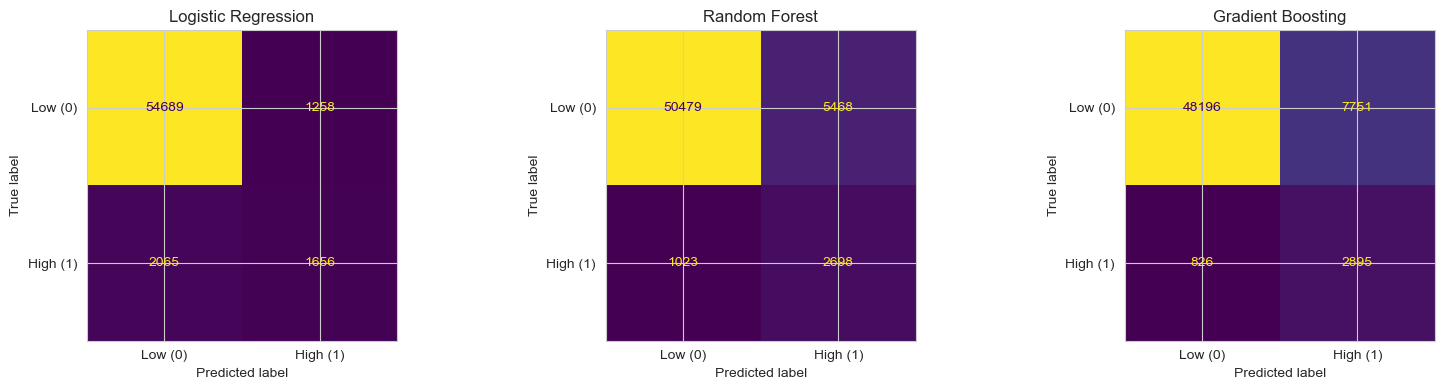

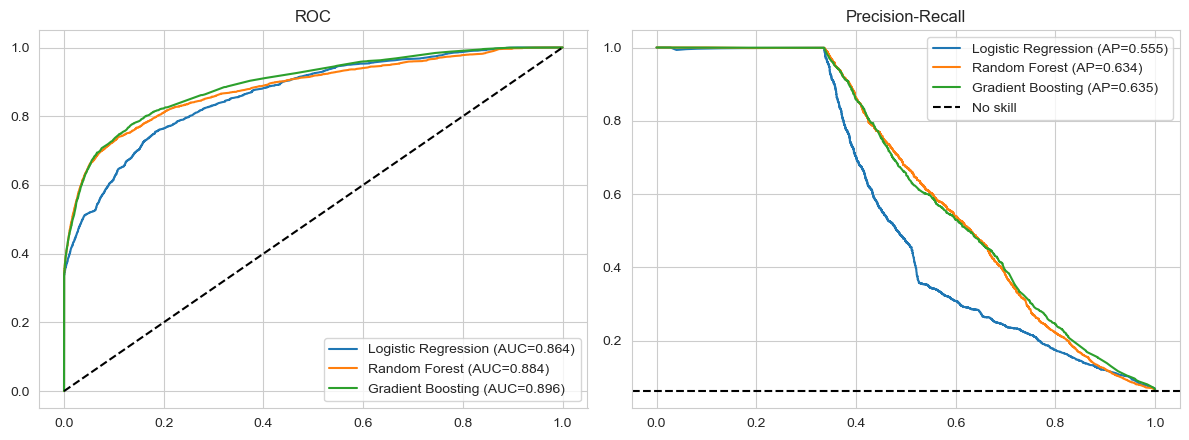

In [28]:
for n in final:
    print("="*60); print(n, "| threshold =", round(thr[n],4))
    print(classification_report(y_test, preds[n], target_names=["Low risk (0)","High risk (1)"], zero_division=0))
fig, ax = plt.subplots(1,3, figsize=(16,4))
for a,n in zip(ax, final):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds[n]), display_labels=["Low (0)","High (1)"]).plot(ax=a, colorbar=False, values_format="d"); a.set_title(n)
save_show("confusion_matrices")
fig, ax = plt.subplots(1,2, figsize=(12,4.5))
for n,sc in scores.items():
    fpr,tpr,_ = roc_curve(y_test, sc); ax[0].plot(fpr,tpr,label=f"{n} (AUC={roc_auc_score(y_test,sc):.3f})")
    p,r,_ = precision_recall_curve(y_test, sc); ax[1].plot(r,p,label=f"{n} (AP={average_precision_score(y_test,sc):.3f})")
ax[0].plot([0,1],[0,1],"k--"); ax[0].set_title("ROC"); ax[0].legend()
ax[1].axhline(y_test.mean(), color="k", ls="--", label="No skill"); ax[1].set_title("Precision-Recall"); ax[1].legend()
save_show("roc_pr_curves")

## 11. Interpretability
Permutation importance (drop in PR-AUC when a feature is shuffled) on the test set. This shows what the model *relies on*, not what *causes* investors to reduce holdings.

Best model by test PR-AUC: Gradient Boosting
                  Feature  Importance      Std
4      prev_users_holding     0.32996  0.00699
1        prev_growth_rate     0.12891  0.00624
6            growth_vol_7     0.10848  0.00933
0  prev_popularity_change     0.02733  0.00336
3           prev_momentum     0.00624  0.00110
5            down_count_7     0.00313  0.00073
2        prev_rolling_avg     0.00135  0.00084


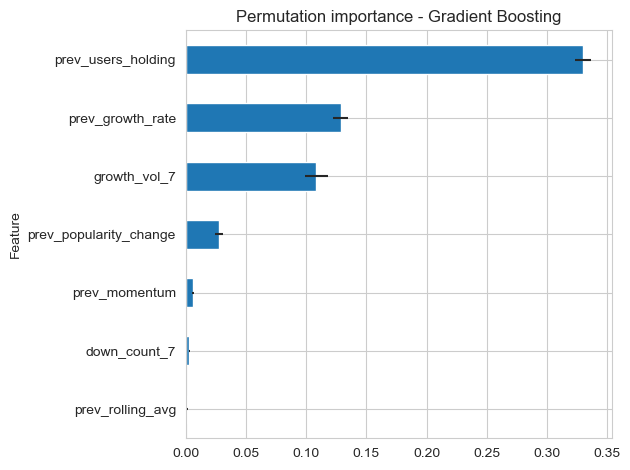

In [29]:
best_name = comparison.drop(index=list(base.keys()))["PR_AUC"].idxmax()
print("Best model by test PR-AUC:", best_name)
def perm_importance(model, X, y, n_repeats=5, seed=RANDOM_STATE):
    
    rng = np.random.RandomState(seed); y = np.asarray(y)
    base_score = average_precision_score(y, model.predict_proba(X)[:, 1])
    rows = []
    for f in X.columns:
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy(); Xp[f] = rng.permutation(Xp[f].values)
            drops.append(base_score - average_precision_score(y, model.predict_proba(Xp)[:, 1]))
        rows.append((f, np.mean(drops), np.std(drops)))
    return pd.DataFrame(rows, columns=["Feature", "Importance", "Std"])

imp = perm_importance(final[best_name], X_test.iloc[::3], y_test.iloc[::3]).sort_values("Importance", ascending=False)
print(imp.round(5)); imp.to_csv("outputs/permutation_importance.csv", index=False)
imp.plot(x="Feature", y="Importance", kind="barh", xerr="Std", legend=False, title=f"Permutation importance - {best_name}")
plt.gca().invert_yaxis(); save_show("permutation_importance")

## 11b. 
Permutation importance ranks `prev_users_holding` first. This cell checks how much predictive power comes from (a) knowing only which stock it is (its training-period decrease rate) and (b) small feature subsets.

In [30]:
rate = train.groupby("name")["risk"].mean()
sc = test["name"].map(rate).fillna(train["risk"].mean())
chk = {"Stock-identity base rate (train decrease rate per stock)": (roc_auc_score(y_test, sc), average_precision_score(y_test, sc))}
Xy = pd.concat([X_train, X_val]); yy = pd.concat([y_train, y_val])
for label, feats in [("Gradient Boosting: prev_users_holding only", ["prev_users_holding"]),
                     ("Gradient Boosting: top 3 features", ["prev_users_holding","prev_growth_rate","growth_vol_7"]),
                     ("Gradient Boosting: all 7 features", FEATURES)]:
    m = GradientBoostingClassifier(n_estimators=100, max_depth=2, learning_rate=0.1, random_state=RANDOM_STATE)
    m.fit(Xy[feats], yy, sample_weight=compute_sample_weight("balanced", yy))
    p = m.predict_proba(X_test[feats])[:, 1]
    chk[label] = (roc_auc_score(y_test, p), average_precision_score(y_test, p))
sanity = pd.DataFrame(chk, index=["ROC_AUC", "PR_AUC"]).T.round(4)
sanity.to_csv("outputs/sanity_check_size_identity.csv"); sanity

,ROC_AUC,PR_AUC
Stock-identity base rate (train decrease rate per stock),0.7661,0.1475
Gradient Boosting: prev_users_holding only,0.8054,0.1997
Gradient Boosting: top 3 features,0.8949,0.6275
Gradient Boosting: all 7 features,0.8959,0.6345


## 11c. Data-quality check: the CIG feed artifact


In [31]:
cig = clean[clean["name"] == "CIG"].sort_values("timestamp")
print(cig[cig["timestamp"] >= "2019-09-01"].head(8)[["timestamp", "users_holding"]].to_string(index=False))
big = data[data["growth_rate"] > 100]
print("\nRows with growth_rate > 100:", len(big), "| by stock:", big["name"].value_counts().to_dict())

share = pd.DataFrame({p: {"Total decreases": int((d["risk"] == 1).sum()),
                          "CIG decreases": int(((d["risk"] == 1) & (d["name"] == "CIG")).sum()),
                          "CIG share of decreases": round(float(((d["risk"] == 1) & (d["name"] == "CIG")).sum() / (d["risk"] == 1).sum()), 4)}
                      for p, d in [("train", train), ("val", val), ("test", test)]}).T
print(); print(share)

gbp = {k: v for k, v in tuned["Gradient Boosting"].best_params_.items()}
def fit_gb(X, y):
    m = GradientBoostingClassifier(random_state=RANDOM_STATE, **gbp)
    return m.fit(X, y, sample_weight=compute_sample_weight("balanced", y))
Xtv, ytv, ntv = pd.concat([X_train, X_val]), pd.concat([y_train, y_val]), pd.concat([train["name"], val["name"]])
te_mask = (test["name"] != "CIG").values
m_all = fit_gb(Xtv, ytv);                         p_all = m_all.predict_proba(X_test)[:, 1]
m_nocig = fit_gb(Xtv[(ntv != "CIG").values], ytv[(ntv != "CIG").values]); p_nocig = m_nocig.predict_proba(X_test[te_mask])[:, 1]
rows = {
 "Trained with CIG, tested on all stocks":         (y_test, p_all),
 "Trained with CIG, tested without CIG":           (y_test[te_mask], p_all[te_mask]),
 "Trained without CIG, tested without CIG":        (y_test[te_mask], p_nocig)}
out = pd.DataFrame({k: {"Test rows": len(v[0]), "Share of decreases": round(float(np.mean(v[0])), 4),
                        "ROC_AUC": round(roc_auc_score(*v), 4), "PR_AUC": round(average_precision_score(*v), 4)}
                    for k, v in rows.items()}).T
out.to_csv("outputs/cig_sensitivity.csv"); out

          timestamp  users_holding
2019-09-01 00:43:40              3
2019-09-01 00:43:42           3497
2019-09-01 01:43:37              3
2019-09-01 01:43:39           3497
2019-09-01 02:43:38              3
2019-09-01 02:43:40           3497
2019-09-01 03:43:38              3
2019-09-01 03:43:40           3497

Rows with growth_rate > 100: 2970 | by stock: {'CIG': 2970}

       Total decreases  CIG decreases  CIG share of decreases
train          12984.0         1156.0                  0.0890
val             4450.0         1763.0                  0.3962
test            3721.0         1347.0                  0.3620


,Test rows,Share of decreases,ROC_AUC,PR_AUC
"Trained with CIG, tested on all stocks",59668.0,0.0624,0.8959,0.6345
"Trained with CIG, tested without CIG",56421.0,0.0421,0.8375,0.2643
"Trained without CIG, tested without CIG",56421.0,0.0421,0.8380,0.2686


## 11d
(a) zero-holder rows removed during cleaning, (b) all three models with and without CIG on the test period, (c) models trained on the training period only, scored on the validation period with and without CIG.

In [32]:

z = clean[clean["users_holding"] == 0]
print("Real rows:", len(clean), "| modelling rows:", len(data), "| removed:", len(clean) - len(data))
print("Rows with users_holding == 0:", len(z), "| by stock:", z["name"].value_counts().head(5).to_dict())


def make_model(name):
    p = tuned[name].best_params_
    if name == "Logistic Regression":
        return Pipeline([("sc", StandardScaler()), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", C=p["clf__C"], random_state=RANDOM_STATE))])
    if name == "Random Forest":
        return RandomForestClassifier(class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1, **p)
    return GradientBoostingClassifier(random_state=RANDOM_STATE, **p)

def fit_named(name, X, y):
    m = make_model(name)
    return m.fit(X, y, sample_weight=compute_sample_weight("balanced", y)) if name == "Gradient Boosting" else m.fit(X, y)

Xtv = pd.concat([X_train, X_val]); ytv = pd.concat([y_train, y_val])
tm = (test["name"] != "CIG").values; vm = (val["name"] != "CIG").values
rows_b, rows_c = {}, {}
for n in ["Logistic Regression", "Random Forest", "Gradient Boosting"]:
    p = fit_named(n, Xtv, ytv).predict_proba(X_test)[:, 1]
    rows_b[n] = {"ROC_all": roc_auc_score(y_test, p), "ROC_noCIG": roc_auc_score(y_test[tm], p[tm]),
                 "PR_all": average_precision_score(y_test, p), "PR_noCIG": average_precision_score(y_test[tm], p[tm])}
    pv = fit_named(n, X_train, y_train).predict_proba(X_val)[:, 1]
    rows_c[n] = {"ROC_val_all": roc_auc_score(y_val, pv), "ROC_val_noCIG": roc_auc_score(y_val[vm], pv[vm]),
                 "PR_val_all": average_precision_score(y_val, pv), "PR_val_noCIG": average_precision_score(y_val[vm], pv[vm])}
res_b = pd.DataFrame(rows_b).T.round(4); res_c = pd.DataFrame(rows_c).T.round(4)
res_b.to_csv("outputs/cig_all_models_test.csv"); res_c.to_csv("outputs/cig_all_models_validation.csv")
print("TEST PERIOD (trained on train + validation):"); print(res_b)
print("\nVALIDATION PERIOD (trained on training only):"); print(res_c)

Real rows: 404717 | modelling rows: 394705 | removed: 10012
Rows with users_holding == 0: 9603 | by stock: {'XOXO': 9424, 'BIBL': 160, 'AAAU': 7, 'DMB': 6, 'XPEL': 4}
TEST PERIOD (trained on train + validation):
                     ROC_all  ROC_noCIG  PR_all  PR_noCIG
Logistic Regression   0.8644     0.7891  0.5550    0.1546
Random Forest         0.8836     0.8178  0.6342    0.2680
Gradient Boosting     0.8959     0.8375  0.6345    0.2643

VALIDATION PERIOD (trained on training only):
                     ROC_val_all  ROC_val_noCIG  PR_val_all  PR_val_noCIG
Logistic Regression       0.8499         0.7907      0.3587        0.1652
Random Forest             0.8372         0.8196      0.3096        0.2902
Gradient Boosting         0.8194         0.8363      0.2573        0.2907


## 12. the model and prediction function

In [33]:
joblib.dump({"model":final[best_name],"features":FEATURES,"threshold":float(thr[best_name]),"model_name":best_name}, "outputs/risk_model.joblib")

def predict_risk(history):
    """history: DataFrame ['timestamp','users_holding'] for ONE stock, oldest first, >= 16 consecutive observations.
    Returns the probability that the NEXT observation shows a decrease in holders."""
    art = joblib.load("outputs/risk_model.joblib")
    s = history.sort_values("timestamp")["users_holding"].astype(float).reset_index(drop=True)
    chg = s.diff(1); gr = s.pct_change(1)
    f = pd.DataFrame({"prev_popularity_change":chg, "prev_growth_rate":gr, "prev_rolling_avg":s.rolling(7).mean(),
                      "prev_momentum":s.diff(7), "prev_users_holding":s,
                      "down_count_7":(chg<0).astype(float).rolling(7).sum(), "growth_vol_7":gr.rolling(7).std()})
    row = f[art["features"]].iloc[[-1]].replace([np.inf,-np.inf], np.nan)
    if row.isna().any(axis=None): raise ValueError("Not enough valid history.")
    p = float(art["model"].predict_proba(row)[:,1][0])
    return {"probability_of_decrease": round(p,4), "label": "High risk" if p >= art["threshold"] else "Low risk"}

ex = clean[clean["name"]==clean["name"].iloc[0]].tail(30)[["timestamp","users_holding"]]
predict_risk(ex)

{'probability_of_decrease': 0.2664, 'label': 'Low risk'}

## 12b. Export for the R dashboard

In [34]:
import json
from sklearn.pipeline import Pipeline as _Pipeline

art = joblib.load("outputs/risk_model.joblib")
FEATS = art["features"]; THR = float(art["threshold"])

def _features(h):
    s = pd.Series(np.asarray(h, dtype=float)); chg = s.diff(1); gr = chg / s.shift(1)
    f = pd.DataFrame({"prev_popularity_change": chg, "prev_growth_rate": gr, "prev_rolling_avg": s.rolling(7).mean(),
                      "prev_momentum": s.diff(7), "prev_users_holding": s, "down_count_7": (chg < 0).astype(float).rolling(7).sum(),
                      "growth_vol_7": gr.replace([np.inf, -np.inf], np.nan).rolling(7).std()})
    return f.replace([np.inf, -np.inf], np.nan)

parts, qrows = [], []
for nm, g in clean.groupby("name"):
    g = g.sort_values("timestamp").reset_index(drop=True)
    f = _features(g["users_holding"].values); ok = f[FEATS].notna().all(axis=1).values
    p = np.full(len(g), np.nan)
    if ok.any(): p[ok] = art["model"].predict_proba(f.loc[ok, FEATS])[:, 1]
    nxt = g["users_holding"].shift(-1)
    parts.append(pd.DataFrame({"name": nm, "timestamp": g["timestamp"], "users_holding": g["users_holding"],
                               "probability": p.round(5),
                               "alert": np.where(np.isnan(p), np.nan, (p >= THR).astype(float)),
                               "next_decrease": np.where(nxt.isna(), np.nan, (nxt < g["users_holding"]).astype(float))}))
    s = g["users_holding"].astype(float); pct = (s.diff() / s.shift(1)).replace([np.inf, -np.inf], np.nan)
    ext = int((pct.abs() > 10).sum()); zs = float((s == 0).mean()); why = []
    if ext >= 20: why.append(f"{ext} jumps of more than 1,000% between consecutive readings")
    if zs > 0.25: why.append(f"{zs:.0%} of readings show zero holders")
    qrows.append({"name": nm, "observations": len(s), "extreme_jumps": ext, "zero_share": round(zs, 4),
                  "data_quality_flag": int(bool(why)), "flag_reason": "; ".join(why)})
pd.concat(parts).to_csv("outputs/dashboard_scores.csv", index=False)
pd.DataFrame(qrows).to_csv("outputs/dashboard_quality.csv", index=False)

def _tree(t, leaf):
    return {"left": t.children_left.tolist(), "right": t.children_right.tolist(), "feature": t.feature.tolist(),
            "threshold": t.threshold.tolist(), "value": leaf.tolist()}

mdl = art["model"]
export = {"model_name": art.get("model_name", ""), "features": FEATS, "threshold": THR}
if isinstance(mdl, _Pipeline):
    sc, lr = mdl.named_steps["sc"], mdl.named_steps["clf"]
    export.update(type="lr", mean=sc.mean_.tolist(), scale=sc.scale_.tolist(), coef=lr.coef_[0].tolist(), intercept=float(lr.intercept_[0]))
elif isinstance(mdl, RandomForestClassifier):
    export.update(type="rf", trees=[_tree(e.tree_, e.tree_.value[:, 0, 1] / e.tree_.value[:, 0, :].sum(axis=1)) for e in mdl.estimators_])
elif isinstance(mdl, GradientBoostingClassifier):
    x0 = X_test.iloc[[0]][FEATS]
    contrib = sum(e.tree_.value[e.apply(x0.values.astype(np.float32))[0], 0, 0] for e in mdl.estimators_[:, 0])
    init = float(mdl.decision_function(x0)[0] - mdl.learning_rate * contrib)
    export.update(type="gb", init=init, learning_rate=float(mdl.learning_rate),
                  trees=[_tree(e.tree_, e.tree_.value[:, 0, 0]) for e in mdl.estimators_[:, 0]])
else:
    raise ValueError("Unsupported model type for export")
json.dump(export, open("outputs/model_export.json", "w"))
print("Exported:", export["type"], "| scores:", sum(len(p) for p in parts), "rows | flagged stocks:", [r["name"] for r in qrows if r["data_quality_flag"]])

Exported: gb | scores: 404717 rows | flagged stocks: ['CIG', 'XOXO']


## 13. Limitations 
* `Risk` is a **proxy**: a fall in the number of holders, not realised profit or loss. The dataset has no prices, trades or investor identities.
* The data are Robinhood (US), May 2018 – Feb 2020, for 31 tickers, aggregated per stock — so the model predicts stock-level outflow, not individual investor risk. EasyEquities/South African generalisation is untested.
* Only ~5% of observations are decreases, so accuracy is misleading; precision/recall/PR-AUC are the relevant metrics.
* Window lengths (7 observations), split fractions and the tuning grid are design choices.

In [35]:
import sklearn
import sys

print("Python:", sys.version)
print("Scikit-learn:", sklearn.__version__)

Python: 3.12.4 | packaged by Anaconda, Inc. | (main, Jun 18 2024, 15:03:56) [MSC v.1929 64 bit (AMD64)]
Scikit-learn: 1.4.2
